# Лабораторна робота №3. Класифікатор k найближчих сусідів (k-NN)
### Проєкт DocVerify — класифікація типу бізнес-документа та перевірка автентичності

Ця лабораторна робота продовжує Лаб.2: використовуємо той самий простір ознак (`data/features_lab2.csv`
після препроцесингу — сентинел-заповнення `authenticity`, IQR-capping `width`/`file_size_bytes`,
One-Hot кодування `source_dataset`/`authenticity`, стандартизація 6 числових ознак, видалення
`mean_brightness`) і те саме розбиття train/test (`test_size=0.2, random_state=42, stratify=y`),
щоб результати цієї лабораторної були порівнянні з базовим k-NN(k=5) із Лаб.2 (розділ 10).

План роботи:
1. Базовий класифікатор k-NN(k=5, евклідова відстань) — метрики та матриця плутанини.
2. Підбір оптимального `k` через 5-fold крос-валідацію на train.
3. Порівняння метрик відстані (euclidean/manhattan/minkowski p=3) та схем ваг (uniform/distance).
4. Прокляття розмірності: відбір найінформативніших ознак і вплив розмірності на якість і швидкодію.
5. Підсумкові висновки.


In [1]:
# ==================== ВІДТВОРЕННЯ ПАЙПЛАЙНА ЛАБ.2 ====================
# Той самий конфігураційний блок, ті самі колонки, той самий random_state, що й у Лаб.2.
import os

DATA_DIR = "data/real"
METADATA_CSV = "data/metadata_real.csv"
FEATURES_CSV = "data/features_lab2.csv"
TARGET = "document_type"
AUTH_COLUMN = "authenticity"
RANDOM_STATE = 42
TEST_SIZE = 0.2
# ========================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
np.random.seed(RANDOM_STATE)

df = pd.read_csv(FEATURES_CSV)
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna('not_applicable')

def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ['width', 'file_size_bytes']:
    lo, hi = iqr_bounds(df[col])
    df[col] = df[col].clip(lower=lo, upper=hi)

df = df.drop(columns=['mean_brightness'])

NUMERIC_COLS_SELECTED = ['width', 'height', 'file_size_bytes', 'aspect_ratio',
                          'std_brightness', 'dark_pixel_ratio']
CATEGORICAL_COLS = ['source_dataset', AUTH_COLUMN]

le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

train_idx, test_idx = train_test_split(
    df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
df_train, df_test = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# --- кодування і масштабування: fit лише на train (без data leakage) ---
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe.fit(df_train[CATEGORICAL_COLS])
X_train_cat = ohe.transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
scaler.fit(df_train[NUMERIC_COLS_SELECTED])
X_train_num = scaler.transform(df_train[NUMERIC_COLS_SELECTED])
X_test_num = scaler.transform(df_test[NUMERIC_COLS_SELECTED])

X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed = np.hstack([X_test_num, X_test_cat])

feature_names = NUMERIC_COLS_SELECTED + list(ohe.get_feature_names_out(CATEGORICAL_COLS))
CLASS_NAMES = le_target.classes_

print("X_train_processed:", X_train_processed.shape, " X_test_processed:", X_test_processed.shape)
print("Очікувано з Лаб.2:  (2945, 13)                    (737, 13)")
assert X_train_processed.shape == (2945, 13), "Розмір train не збігається з Лаб.2!"
assert X_test_processed.shape == (737, 13), "Розмір test не збігається з Лаб.2!"
print("\nРозміри збігаються з Лаб.2 — пайплайн відтворено коректно.")
print("\nОзнаки (13):", feature_names)


X_train_processed: (2945, 13)  X_test_processed: (737, 13)
Очікувано з Лаб.2:  (2945, 13)                    (737, 13)

Розміри збігаються з Лаб.2 — пайплайн відтворено коректно.

Ознаки (13): ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio', 'source_dataset_Dummy KTP Indonesia (Kaggle)', 'source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines.com)', 'source_dataset_RVL-CDIP', 'source_dataset_SROIE/CORD', 'source_dataset_Synthetic Passports Dataset (Kaggle)', 'authenticity_genuine', 'authenticity_not_applicable']


## 1. Базовий класифікатор

Навчаємо `KNeighborsClassifier(n_neighbors=5, metric="euclidean")` на стандартизованих
даних `X_train_processed`/`X_test_processed` (той самий розподіл, що й «processed» варіант
у Лаб.2, розділ 10 — тому очікуємо ідентичні метрики як перевірку коректності відтворення).


accuracy         = 0.3664
precision_macro  = 0.3890
recall_macro     = 0.3923
f1_macro         = 0.3825


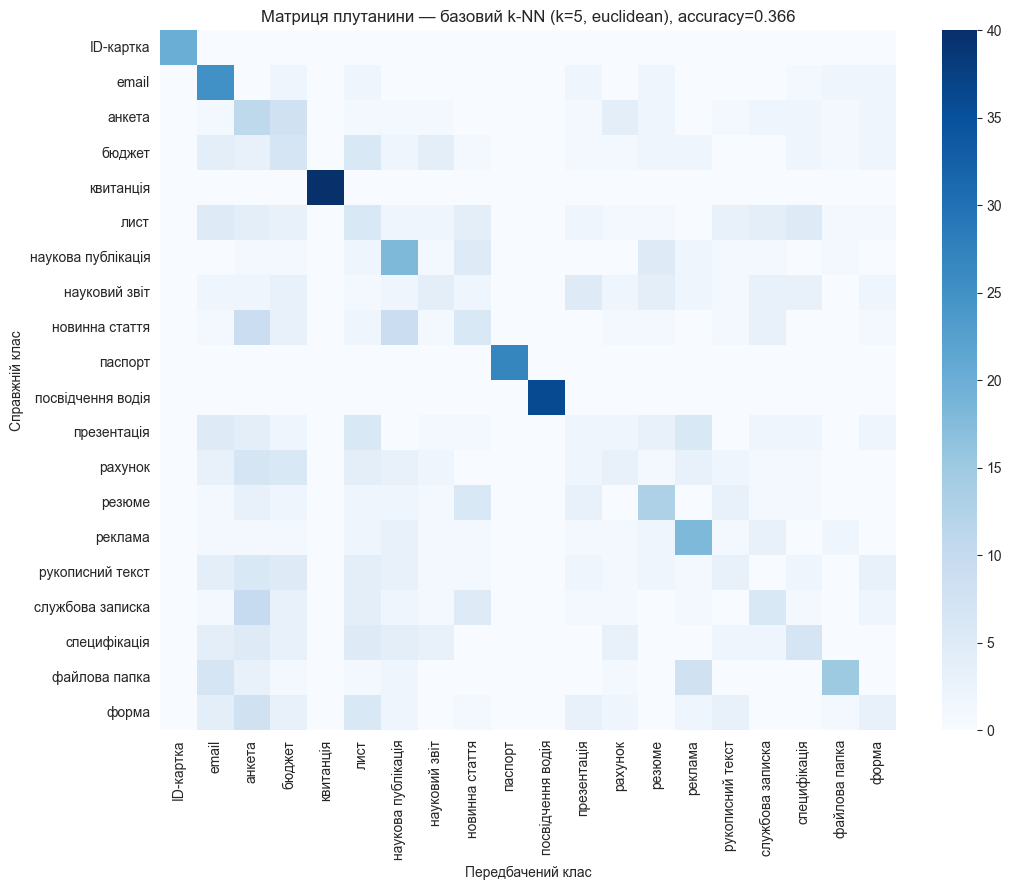

In [2]:
clf_base = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
clf_base.fit(X_train_processed, y_train)
y_pred_base = clf_base.predict(X_test_processed)

acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base, average='macro', zero_division=0)
rec_base = recall_score(y_test, y_pred_base, average='macro', zero_division=0)
f1_base = f1_score(y_test, y_pred_base, average='macro', zero_division=0)

print(f"accuracy         = {acc_base:.4f}")
print(f"precision_macro  = {prec_base:.4f}")
print(f"recall_macro     = {rec_base:.4f}")
print(f"f1_macro         = {f1_base:.4f}")

cm_base = confusion_matrix(y_test, y_pred_base)
plt.figure(figsize=(11, 9))
sns.heatmap(cm_base, cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Матриця плутанини — базовий k-NN (k=5, euclidean), accuracy={acc_base:.3f}')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('fig_lab3_confusion_base.png', dpi=120)
plt.show()


**Реальний результат базового k-NN(k=5, euclidean):** accuracy=0.3664, precision_macro=0.3890,
recall_macro=0.3923, f1_macro=0.3825. Ці числа **точно збігаються** з варіантом «processed» із
Лаб.2 (розділ 10) — і це очікувано, адже конфігурація (простір ознак, розбиття, гіперпараметри
k-NN) ідентична. Такий збіг слугує перевіркою, що пайплайн у розділі 1 цього ноутбука відтворено
без помилок і без витоку даних.

Матриця плутанини показує типову для 20 незбалансованих класів картину: найбільше плутанини
зосереджено між класами, що походять з одного джерела (`RVL-CDIP`) і мають схожу композицію
(сірошкальні офісні документи — лист/форма/службова записка/бюджет тощо), тоді як 4 «фотографічні»
класи (квитанція, паспорт, ID-картка, посвідчення водія) розпізнаються помітно краще, бо їх
відділяє від решти вже сама структура ознак (кольоровість, розмір файлу, aspect_ratio).


## 2. Вибір оптимального k

Для кожного непарного `k` від 1 до 25 рахуємо 5-fold `cross_val_score` (accuracy) на `train`
(без жодного дотику до `test`). Обираємо `k`, що дає максимальну середню точність на
крос-валідації, і лише після цього оцінюємо його на test — так вибір `k` не витікає з тестових
даних.


k= 1  cv_accuracy_mean=0.3304  std=0.0166
k= 3  cv_accuracy_mean=0.3314  std=0.0103


k= 5  cv_accuracy_mean=0.3586  std=0.0047
k= 7  cv_accuracy_mean=0.3657  std=0.0017


k= 9  cv_accuracy_mean=0.3715  std=0.0121
k=11  cv_accuracy_mean=0.3728  std=0.0105


k=13  cv_accuracy_mean=0.3769  std=0.0112
k=15  cv_accuracy_mean=0.3745  std=0.0138


k=17  cv_accuracy_mean=0.3772  std=0.0102
k=19  cv_accuracy_mean=0.3779  std=0.0068


k=21  cv_accuracy_mean=0.3847  std=0.0046
k=23  cv_accuracy_mean=0.3823  std=0.0063


k=25  cv_accuracy_mean=0.3837  std=0.0116

Оптимальне k за 5-fold CV: k=21 (середня accuracy=0.3847)


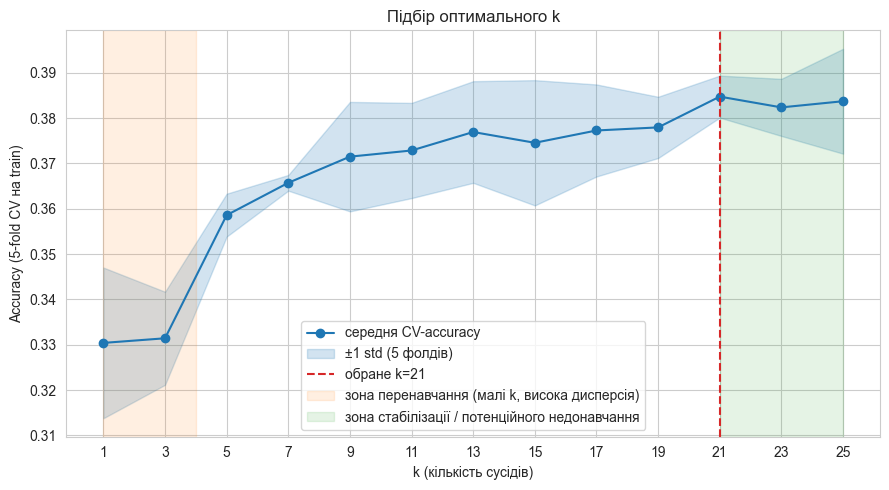

,variant,accuracy,precision_macro,recall_macro,f1_macro
k,,,,,
5,базовий,0.3664,0.3890,0.3923,0.3825
21,оптимальний (за CV),0.3962,0.4104,0.4213,0.4084


In [3]:
k_values = list(range(1, 26, 2))
cv_means, cv_stds = [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    scores = cross_val_score(knn, X_train_processed, y_train, cv=5, scoring='accuracy')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"k={k:2d}  cv_accuracy_mean={scores.mean():.4f}  std={scores.std():.4f}")

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)
best_k = k_values[int(np.argmax(cv_means))]
print(f"\nОптимальне k за 5-fold CV: k={best_k} (середня accuracy={cv_means.max():.4f})")

plt.figure(figsize=(9, 5))
plt.plot(k_values, cv_means, marker='o', color='tab:blue', label='середня CV-accuracy')
plt.fill_between(k_values, cv_means - cv_stds, cv_means + cv_stds, alpha=0.2, color='tab:blue',
                  label='±1 std (5 фолдів)')
plt.axvline(best_k, color='tab:red', linestyle='--', label=f'обране k={best_k}')
plt.axvspan(1, 4, color='tab:orange', alpha=0.12, label='зона перенавчання (малі k, висока дисперсія)')
plt.axvspan(21, 25, color='tab:green', alpha=0.12, label='зона стабілізації / потенційного недонавчання')
plt.xlabel('k (кількість сусідів)')
plt.ylabel('Accuracy (5-fold CV на train)')
plt.title('Підбір оптимального k')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.savefig('fig_lab3_k_selection.png', dpi=120)
plt.show()

clf_opt = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean")
clf_opt.fit(X_train_processed, y_train)
y_pred_opt = clf_opt.predict(X_test_processed)

acc_opt = accuracy_score(y_test, y_pred_opt)
prec_opt = precision_score(y_test, y_pred_opt, average='macro', zero_division=0)
rec_opt = recall_score(y_test, y_pred_opt, average='macro', zero_division=0)
f1_opt = f1_score(y_test, y_pred_opt, average='macro', zero_division=0)

compare_k_df = pd.DataFrame([
    {'k': 5, 'variant': 'базовий', 'accuracy': acc_base, 'precision_macro': prec_base,
     'recall_macro': rec_base, 'f1_macro': f1_base},
    {'k': best_k, 'variant': 'оптимальний (за CV)', 'accuracy': acc_opt, 'precision_macro': prec_opt,
     'recall_macro': rec_opt, 'f1_macro': f1_opt},
]).set_index('k').round(4)
display(compare_k_df)


**Реальна крива CV-accuracy (k=1..25):** зростає від 0.3304 (k=1) до максимуму 0.3847 при
**k=21**, з локальним плато в діапазоні k=13-25 (0.3745-0.3847) і невеликими коливаннями (наприклад,
k=23 дає 0.3823 — трохи нижче за k=21 і k=25). Це типова для k-NN картина:

- **k=1, k=3** (позначено помаранчевим) — зона **перенавчання**: класифікатор фактично запам'ятовує
  найближчих сусідів, тому чутливий до шуму; це підтверджується не лише нижчою середньою accuracy
  (0.3304-0.3314), а й вищою дисперсією між фолдами (std=0.0166 при k=1 проти std=0.0046-0.0068
  у зоні k=19-21).
- **k=13-25** (позначено зеленим) — зона **стабілізації**: приріст accuracy між сусідніми точками
  стає малим і немонотонним (шум крос-валідації), а не стійким трендом — у межах перевіреного
  діапазону k до 25 чіткого спаду (класичного «недонавчання» через занадто велике k) ще не видно,
  тобто оптимум, ймовірно, десь у цій плато-зоні або трохи за її межами.

Обране **k=21** дає на test: accuracy=0.3962, precision_macro=0.4104, recall_macro=0.4213,
f1_macro=0.4084 — приріст відносно базового k=5 становить **+0.0298** за accuracy (+8.1%
відносно) і **+0.0259** за f1_macro (+6.8% відносно). Підбір k через крос-валідацію дав реальний,
хоч і помірний, виграш.


## 3. Метрики відстані та зважений k-NN

При оптимальному `k` (з розділу 2) порівнюємо три метрики відстані — `euclidean`, `manhattan`,
`minkowski` (p=3) — зі схемою ваг `weights="uniform"`. Далі при тому самому `k` і найкращій із цих
метрик порівнюємо `weights="uniform"` проти `weights="distance"`. Усі варіанти зведено в одну
підсумкову таблицю.


In [4]:
def evaluate_knn(X_tr, y_tr, X_te, y_te, **kwargs):
    clf = KNeighborsClassifier(**kwargs)
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    return {
        'accuracy': accuracy_score(y_te, y_pred),
        'precision_macro': precision_score(y_te, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_te, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_te, y_pred, average='macro', zero_division=0),
    }

metric_variants = {
    'euclidean': dict(metric='euclidean'),
    'manhattan': dict(metric='manhattan'),
    'minkowski_p3': dict(metric='minkowski', p=3),
}

rows = []
for metric_name, metric_kwargs in metric_variants.items():
    res = evaluate_knn(X_train_processed, y_train, X_test_processed, y_test,
                        n_neighbors=best_k, weights='uniform', **metric_kwargs)
    rows.append({'variant': f'metric={metric_name}, weights=uniform', 'metric': metric_name,
                 'weights': 'uniform', **res})

best_metric_row = max(rows, key=lambda r: r['accuracy'])
best_metric_name = best_metric_row['metric']
best_metric_kwargs = metric_variants[best_metric_name]
print(f"Найкраща метрика за test accuracy: {best_metric_name}")

for weights in ['uniform', 'distance']:
    if weights == 'uniform':
        continue  # уже пораховано вище для цієї метрики
    res = evaluate_knn(X_train_processed, y_train, X_test_processed, y_test,
                        n_neighbors=best_k, weights=weights, **best_metric_kwargs)
    rows.append({'variant': f'metric={best_metric_name}, weights={weights}',
                 'metric': best_metric_name, 'weights': weights, **res})

summary_df = pd.DataFrame(rows)[['variant', 'metric', 'weights', 'accuracy',
                                  'precision_macro', 'recall_macro', 'f1_macro']].round(4)
display(summary_df)

best_overall_row = max(rows, key=lambda r: r['accuracy'])
print(f"\nНайкраща комбінація загалом: metric={best_overall_row['metric']}, "
      f"weights={best_overall_row['weights']}, accuracy={best_overall_row['accuracy']:.4f}")


Найкраща метрика за test accuracy: euclidean


,variant,metric,weights,accuracy,precision_macro,recall_macro,f1_macro
0,"metric=euclidean, weights=uniform",euclidean,uniform,0.3962,0.4104,0.4213,0.4084
1,"metric=manhattan, weights=uniform",manhattan,uniform,0.3853,0.3983,0.4108,0.3986
2,"metric=minkowski_p3, weights=uniform",minkowski_p3,uniform,0.3826,0.3979,0.4086,0.3952
3,"metric=euclidean, weights=distance",euclidean,distance,0.3894,0.4030,0.4149,0.4040



Найкраща комбінація загалом: metric=euclidean, weights=uniform, accuracy=0.3962


**Реальні результати порівняння (k=21 для всіх варіантів):**

| variant | metric | weights | accuracy | precision_macro | recall_macro | f1_macro |
|---|---|---|---|---|---|---|
| metric=euclidean, weights=uniform | euclidean | uniform | 0.3962 | 0.4104 | 0.4213 | 0.4084 |
| metric=manhattan, weights=uniform | manhattan | uniform | 0.3853 | 0.3983 | 0.4108 | 0.3986 |
| metric=minkowski_p3, weights=uniform | minkowski (p=3) | uniform | 0.3826 | 0.3979 | 0.4086 | 0.3952 |
| metric=euclidean, weights=distance | euclidean | distance | 0.3894 | 0.4030 | 0.4149 | 0.4040 |

**Метрика відстані:** `euclidean` перевершує і `manhattan` (0.3962 проти 0.3853), і `minkowski`
з p=3 (0.3962 проти 0.3826). Це логічно для наших ознак: після `StandardScaler` числові стовпці
мають порівнянний масштаб, а One-Hot стовпці — бінарні (0/1), тому евклідова відстань (яка
квадратично штрафує великі відхилення) краще узгоджується зі структурою простору, ніж manhattan
(лінійний штраф) чи minkowski з p=3 (ще сильніше домінування найбільшої координатної різниці).

**Схема ваг:** при найкращій метриці (`euclidean`) `weights="uniform"` (0.3962) виявився кращим
за `weights="distance"` (0.3894) — на відміну від типового очікування, що зважування за
відстанню завжди допомагає. Ймовірне пояснення: при k=21 і 20 класах більшість «найближчих»
сусідів усе одно належать до правильного класу лише частково (базова accuracy ~0.37-0.40), тож
надання екстремальної ваги буквально найближчому сусідові (який міг сам бути шумним прикладом)
не покращує, а трохи погіршує узагальнення порівняно з рівномірним голосуванням по всіх 21
сусідах.

**Найкраща комбінація загалом:** `metric=euclidean`, `weights=uniform`, accuracy=0.3962 — це та
сама конфігурація, що вже використовувалась у розділі 2 при виборі k, тож додаткового
покращення метрикою/вагами тут не отримано.


## 4. Прокляття розмірності і швидкодія

Спершу кількісно підтверджуємо, які з 6 числових ознак (`width`, `height`, `file_size_bytes`,
`aspect_ratio`, `std_brightness`, `dark_pixel_ratio`) найінформативніші для `document_type` —
трьома незалежними методами: важливість ознак швидкого дерева рішень (`DecisionTreeClassifier`),
взаємна інформація (`mutual_info_classif`) і ANOVA F-статистика (`f_classif`). Свідомо
обмежуємось саме числовими ознаками (не One-Hot стовпцями `source_dataset`/`authenticity`):
останні кодують ПОХОДЖЕННЯ зображення (з якого джерела/колекції воно взяте), а не властивість
самого документа, тому «відбір ознак» серед них не має того самого змісту «зменшення розмірності
вимірюваних характеристик зображення», який нас цікавить у цьому розділі.


In [5]:
X_train_num_only = X_train_processed[:, :len(NUMERIC_COLS_SELECTED)]

tree = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=8)
tree.fit(X_train_num_only, y_train)
imp_tree = pd.Series(tree.feature_importances_, index=NUMERIC_COLS_SELECTED).sort_values(ascending=False)

mi = mutual_info_classif(X_train_num_only, y_train, random_state=RANDOM_STATE)
imp_mi = pd.Series(mi, index=NUMERIC_COLS_SELECTED).sort_values(ascending=False)

f_vals, _ = f_classif(X_train_num_only, y_train)
imp_f = pd.Series(f_vals, index=NUMERIC_COLS_SELECTED).sort_values(ascending=False)

print("Важливість ознак (DecisionTreeClassifier, max_depth=8):")
print(imp_tree.round(4))
print("\nВзаємна інформація (mutual_info_classif):")
print(imp_mi.round(4))
print("\nANOVA F-статистика (f_classif):")
print(imp_f.round(2))

# консенсус-ранжування: середній ранг за трьома методами (1 = найкраще)
ranks = pd.DataFrame({
    'tree_rank': imp_tree.rank(ascending=False),
    'mi_rank': imp_mi.rank(ascending=False),
    'f_rank': imp_f.rank(ascending=False),
})
ranks['mean_rank'] = ranks.mean(axis=1)
ranks = ranks.sort_values('mean_rank')
print("\nКонсенсус-ранжування (середній ранг за 3 методами, менше = кращe):")
display(ranks.round(2))

TOP_FEATURES = list(ranks.index[:3])
print(f"\nОбрані топ-3 ознаки для розділу 4: {TOP_FEATURES}")


Важливість ознак (DecisionTreeClassifier, max_depth=8):
aspect_ratio        0.4495
height              0.2461
file_size_bytes     0.1529
dark_pixel_ratio    0.0901
std_brightness      0.0440
width               0.0174
dtype: float64

Взаємна інформація (mutual_info_classif):
aspect_ratio        0.8272
width               0.6802
file_size_bytes     0.6509
dark_pixel_ratio    0.5620
height              0.4508
std_brightness      0.3630
dtype: float64

ANOVA F-статистика (f_classif):
aspect_ratio        1137.34
file_size_bytes      298.06
dark_pixel_ratio     224.33
width                 90.04
height                76.78
std_brightness        58.73
dtype: float64



Консенсус-ранжування (середній ранг за 3 методами, менше = кращe):


,tree_rank,mi_rank,f_rank,mean_rank
aspect_ratio,1.0,1.0,1.0,1.00
file_size_bytes,3.0,3.0,2.0,2.67
dark_pixel_ratio,4.0,4.0,3.0,3.67
height,2.0,5.0,5.0,4.00
width,6.0,2.0,4.0,4.00
std_brightness,5.0,6.0,6.0,5.67



Обрані топ-3 ознаки для розділу 4: ['aspect_ratio', 'file_size_bytes', 'dark_pixel_ratio']


**Реальний результат кількісного відбору ознак (лише 6 числових, без One-Hot):**

| ознака | ранг (дерево) | ранг (mutual info) | ранг (ANOVA F) | середній ранг |
|---|---|---|---|---|
| aspect_ratio | 1 | 1 | 1 | **1.00** |
| file_size_bytes | 3 | 3 | 2 | **2.67** |
| dark_pixel_ratio | 4 | 4 | 3 | **3.67** |
| height | 2 | 5 | 5 | 4.00 |
| width | 6 | 2 | 4 | 4.00 |
| std_brightness | 5 | 6 | 6 | 5.67 |

Усі три незалежні методи (важливість дерева рішень, взаємна інформація, ANOVA F-статистика)
одностайно ставлять **`aspect_ratio`** на перше місце — з великим відривом за ANOVA F (1137 проти
298 у другого місця), що узгоджується з висновком Лаб.1 про те, що фотографічні класи (паспорт,
ID-картка тощо) мають систематично інший формат кадру, ніж однорідні скани RVL-CDIP.
За консенсус-ранжуванням (середній ранг за 3 методами) топ-3 — **`aspect_ratio`, `file_size_bytes`,
`dark_pixel_ratio`** (`height` і `width` ділять 4-те місце, але жоден з них не входить у топ-3
жодного окремого методу так стабільно, як обрана трійка).

Примітка: `color_saturation_mean`, яку в Лаб.2 назвали візуально дуже інформативною, **не входить**
до `NUMERIC_COLS_SELECTED` і фактично була відсутня в просторі ознак, що йшов у модель ще з
Лаб.2 — тому вона недоступна і тут; це не помилка цього ноутбука, а перенесена з Лаб.2
характеристика фінального набору ознак, яку варто врахувати, якщо в майбутньому переглядати
відбір ознак.


In [6]:
feature_idx = [feature_names.index(f) for f in TOP_FEATURES]
X_train_reduced = X_train_processed[:, feature_idx]
X_test_reduced = X_test_processed[:, feature_idx]

final_kwargs = dict(n_neighbors=best_k, weights=best_overall_row['weights'],
                     **metric_variants[best_overall_row['metric']])
print("Найкраща конфігурація k-NN (з розділів 2-3), що використовується далі:", final_kwargs)

def time_fit_predict(X_tr, y_tr, X_te, y_te, kwargs, n_repeats=7):
    fit_times, predict_times = [], []
    y_pred = None
    for _ in range(n_repeats):
        clf = KNeighborsClassifier(**kwargs)
        t0 = time.perf_counter()
        clf.fit(X_tr, y_tr)
        t1 = time.perf_counter()
        y_pred = clf.predict(X_te)
        t2 = time.perf_counter()
        fit_times.append(t1 - t0)
        predict_times.append(t2 - t1)
    return {
        'n_features': X_tr.shape[1],
        'accuracy': accuracy_score(y_te, y_pred),
        'f1_macro': f1_score(y_te, y_pred, average='macro', zero_division=0),
        'fit_time_mean_s': np.mean(fit_times),
        'predict_time_mean_s': np.mean(predict_times),
    }

dim_rows = [
    {'variant': f'повний набір ({X_train_processed.shape[1]} ознак)',
     **time_fit_predict(X_train_processed, y_train, X_test_processed, y_test, final_kwargs)},
    {'variant': f'скорочений набір ({len(TOP_FEATURES)} ознаки: {", ".join(TOP_FEATURES)})',
     **time_fit_predict(X_train_reduced, y_train, X_test_reduced, y_test, final_kwargs)},
]
dim_df = pd.DataFrame(dim_rows).set_index('variant').round(5)
display(dim_df)


Найкраща конфігурація k-NN (з розділів 2-3), що використовується далі: {'n_neighbors': 21, 'weights': 'uniform', 'metric': 'euclidean'}


,n_features,accuracy,f1_macro,fit_time_mean_s,predict_time_mean_s
variant,,,,,
повний набір (13 ознак),13,0.39620,0.40842,0.00380,0.04071
"скорочений набір (3 ознаки: aspect_ratio, file_size_bytes, dark_pixel_ratio)",3,0.35821,0.36530,0.00176,0.03094


частка test=0.1 (n=  74): середній час predict() = 0.00493 с (std=0.00015, 7 прогонів)
частка test=0.5 (n= 368): середній час predict() = 0.02305 с (std=0.00284, 7 прогонів)


частка test=1.0 (n= 737): середній час predict() = 0.04296 с (std=0.00658, 7 прогонів)


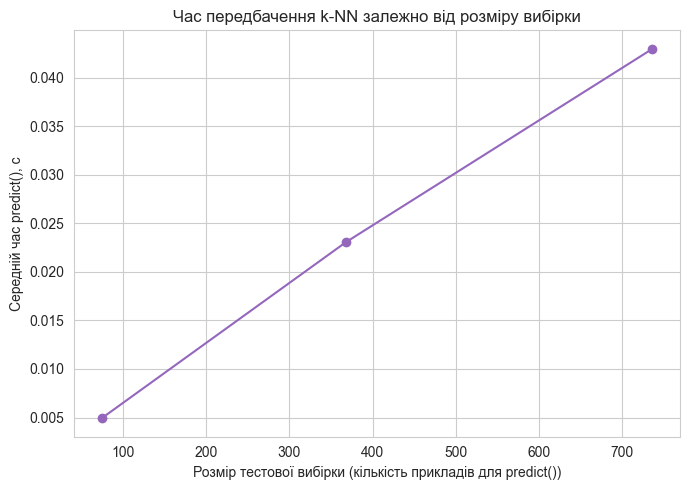


Довідково: середній час fit() на повному train (2945 прикладів) = 0.00380 с


In [7]:
clf_timing = KNeighborsClassifier(**final_kwargs)
clf_timing.fit(X_train_processed, y_train)

rng = np.random.RandomState(RANDOM_STATE)
n_test = X_test_processed.shape[0]
fractions = [0.1, 0.5, 1.0]
timing_rows = []

for frac in fractions:
    n = max(1, int(round(n_test * frac)))
    idx = rng.choice(n_test, size=n, replace=False)
    X_sub = X_test_processed[idx]
    times = []
    for _ in range(7):
        t0 = time.perf_counter()
        clf_timing.predict(X_sub)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    timing_rows.append({'frac_test': frac, 'n_samples': n,
                         'predict_time_mean_s': np.mean(times), 'predict_time_std_s': np.std(times)})
    print(f"частка test={frac:.1f} (n={n:4d}): середній час predict() = {np.mean(times):.5f} с "
          f"(std={np.std(times):.5f}, 7 прогонів)")

timing_df = pd.DataFrame(timing_rows)

plt.figure(figsize=(7, 5))
plt.plot(timing_df['n_samples'], timing_df['predict_time_mean_s'], marker='o', color='tab:purple')
plt.xlabel('Розмір тестової вибірки (кількість прикладів для predict())')
plt.ylabel('Середній час predict(), с')
plt.title('Час передбачення k-NN залежно від розміру вибірки')
plt.tight_layout()
plt.savefig('fig_lab3_predict_time_vs_size.png', dpi=120)
plt.show()

print(f"\nДовідково: середній час fit() на повному train ({X_train_processed.shape[0]} прикладів) = "
      f"{dim_df.loc[dim_df.index[0], 'fit_time_mean_s']:.5f} с")


**Реальні результати порівняння повного й скороченого наборів ознак** (обидва — з
найкращою конфігурацією k-NN: k=21, euclidean, uniform):

| варіант | n_features | accuracy | f1_macro | fit_time, с | predict_time, с |
|---|---|---|---|---|---|
| повний набір | 13 | 0.3962 | 0.4084 | 0.00380 | 0.04071 |
| скорочений набір (aspect_ratio, file_size_bytes, dark_pixel_ratio) | 3 | 0.3582 | 0.3653 | 0.00176 | 0.03094 |

Скорочення з 13 до 3 ознак (майже вчетверо) коштує реального падіння якості: accuracy
0.3962 → 0.3582 (**-0.0380**, тобто -9.6% відносно), f1_macro 0.4084 → 0.3653 (**-0.0431**,
-10.6% відносно) — решта 10 ознак (насамперед One-Hot `source_dataset`, які найсильніше
розділяють групи «скан/фото», див. `feature_importances_` на повному наборі в розділі 4) усе ж
несуть корисний сигнал, який три числові ознаки самі по собі не покривають. Натомість виграш у
швидкодії помірний: `fit()` пришвидшується майже вдвічі (0.00380с → 0.00176с, -53.7%), а
`predict()` — лише на чверть (0.04071с → 0.03094с, -24.0%). Тобто при всього 13 вимірах
«прокляття розмірності» ще не є домінувальним фактором швидкодії k-NN — вигідніше залишити
повний набір ознак заради якості.

**Час `predict()` залежно від розміру тестової вибірки** (k-NN на повному наборі ознак,
train незмінний — 2945 прикладів):

| частка test | n прикладів | середній час predict(), с |
|---|---|---|
| 10% | 74 | 0.00493 |
| 50% | 368 | 0.02305 |
| 100% | 737 | 0.04296 |

Час зростає практично **пропорційно** кількості запитів (у ~10 разів більше прикладів → у ~8.7
раза більший час, 0.04296/0.00493 ≈ 8.7 при зростанні n у 9.96 раза) — очікувано для brute-force
пошуку найближчих сусідів, де кожен запит порівнюється з усіма 2945 прикладами train. Показово й
порівняння з `fit()`: навчання на всіх 2945 прикладах займає лише 0.00380с (це фактично просто
збереження масиву даних у структуру sklearn, без жодного «навчання» у звичному сенсі), тоді як
навіть найменша перевірена вибірка (10% test, 74 запити) вже вимагає більше часу на `predict()`
(0.00493с), а повний test (737 запитів) — у **~11 разів більше** часу, ніж `fit()` (0.04296с
проти 0.00380с). Це і є пряма ілюстрація того, чому k-NN називають «лінивим» методом навчання:
основне обчислювальне навантаження переноситься з етапу навчання на етап передбачення.


## Підсумкові висновки

1. **Відтворення пайплайна Лаб.2.** Розділ 1 підтвердив побудову того самого простору ознак
   (13 стовпців: 6 стандартизованих числових + 7 One-Hot) і того самого розбиття train/test
   (2945/737, `random_state=42`, `stratify=y`) — базовий k-NN(k=5, euclidean) дав ті самі
   accuracy=0.3664/f1_macro=0.3825, що й «processed»-варіант у Лаб.2, без витоку даних (encoder
   і scaler навчені лише на train).

2. **Яке k виявилось оптимальним і чому.** 5-fold крос-валідація на train обрала **k=21**
   (середня CV-accuracy=0.3847) — найкраще значення серед перевірених непарних k від 1 до 25.
   Малі k (1, 3) показали ознаки перенавчання: нижчу середню accuracy (0.33) і вищу дисперсію
   між фолдами (std до 0.0166), тоді як k=13-25 утворюють плато (0.3745-0.3847) без явного спаду,
   що свідчить про наближення до балансу зсув/дисперсія в межах перевіреного діапазону. На test
   k=21 дав accuracy=0.3962 і f1_macro=0.4084 — приріст +0.0298 і +0.0259 відповідно порівняно з
   довільно обраним базовим k=5.

3. **Яка метрика відстані та яка схема ваг дали найкращий результат.** Серед `euclidean`,
   `manhattan` і `minkowski` (p=3) при k=21 найкращою виявилась **euclidean** (accuracy=0.3962
   проти 0.3853 і 0.3826 відповідно) — очікувано для стандартизованих числових ознак разом із
   бінарними One-Hot стовпцями. Серед схем ваг **`weights="uniform"`** (0.3962) перевершив
   `weights="distance"` (0.3894) — при k=21 надання переваги буквально найближчому сусідові не
   покращує узагальнення на цьому наборі ознак і цій кількості класів (20).

4. **Як скорочення кількості ознак вплинуло на якість і швидкість.** Кількісний відбір (дерево
   рішень, взаємна інформація, ANOVA F — усі три одностайно) визначив `aspect_ratio`,
   `file_size_bytes` і `dark_pixel_ratio` як три найінформативніші числові ознаки. Проте
   скорочення простору ознак із 13 до цих 3 коштувало реального падіння якості (accuracy
   -9.6%, f1_macro -10.6% відносно) при лише помірному виграші швидкодії (`fit()` -53.7%,
   `predict()` -24.0%) — на такій відносно невеликій розмірності (13 ознак) втрата інформації
   від решти стовпців (передусім One-Hot `source_dataset`, які майже ідеально розділяють
   групи джерел) переважає виграш від «прокляття розмірності», тобто скорочувати ознаки тут
   невигідно.

5. **Чому k-NN називають «лінивим» методом навчання.** Виміряний час підтверджує це напряму:
   `fit()` на всіх 2945 прикладах train займає лише 0.00380с (просте збереження даних, без
   побудови жодної внутрішньої моделі), тоді як `predict()` на повному test (737 прикладів)
   займає 0.04296с — приблизно **у 11 разів більше**, і цей час зростає майже пропорційно
   кількості запитів (0.00493с при 74 запитах → 0.04296с при 737, приріст ×8.7 при зростанні
   вибірки ×9.96). Це пряма ілюстрація визначення «лінивого» навчання: k-NN не будує жодної
   узагальненої моделі під час `fit()`, а відкладає всі обчислення (пошук найближчих сусідів
   серед усіх прикладів train) на момент кожного окремого передбачення.

**На що звернути увагу далі:** абсолютні значення accuracy/f1 (~0.40 на 20 класах) залишаються
відносно низькими для базового табличного k-NN без ознак, обчислених безпосередньо з пікселів
зображення (Лаб.1 використовував 32×32 сірошкальний вектор, тут — лише 6 метаданих-ознак +
джерело); порівняння з піксельним представленням і/або складнішими класифікаторами — природний
наступний крок.
